**Nombre completo:**
Isaac Vivanco Reyna Vanesa Isaac Vivanco
**Grupo:**
002
**Fecha:**
21/10/26
---

# Laboratorio y Actividades 11 y 12 · Eventos discretos y continuos
**Simulación de Sistemas · Miércoles 21 de octubre de 2026 · segunda hora**

Este notebook tiene dos partes:
- **Parte A · Laboratorio (en clase):** convertimos el algoritmo de la primera hora en código, con reloj, lista de eventos y contadores.
- **Parte B · Actividad 11 (para entregar):** cinco ejercicios que usan la función `simular` de la Parte A.
- **Parte C · Actividad 12 (para entregar):** seis ejercicios con varias corridas y modelo continuo.



# Parte A · Laboratorio

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. El algoritmo
Recibe la hora de llegada y el tiempo de servicio de cada cliente. Regresa la tabla de simulación y los contadores.

- **Lista de eventos:** tuplas `(tiempo, prioridad, tipo, cliente)`. La prioridad 0 hace que, si hay empate, la salida se atienda antes que la llegada.
- **Reloj:** toma el tiempo del evento que sale de la lista.
- **Contadores:** atendidos, espera total y tiempo ocupado.

In [ ]:
def simular(llegadas, servicios):
    reloj = 0.0
    eventos = [(llegadas[0], 1, "llegada", 0)]
    cola = []
    en_ventanilla = None
    atendidos = 0
    espera_total = 0.0
    tiempo_ocupado = 0.0
    registro = []

    def atender(cliente):
        nonlocal en_ventanilla, tiempo_ocupado
        en_ventanilla = cliente
        eventos.append((reloj + servicios[cliente], 0, "salida", cliente))
        tiempo_ocupado += servicios[cliente]

    while eventos:
        eventos.sort()
        reloj, _, tipo, cliente = eventos.pop(0)

        if tipo == "llegada":
            if cliente + 1 < len(llegadas):
                eventos.append((llegadas[cliente + 1], 1, "llegada", cliente + 1))
            if en_ventanilla is None:
                atender(cliente)
            else:
                cola.append(cliente)
        else:  # salida
            atendidos += 1
            en_ventanilla = None
            if cola:
                siguiente = cola.pop(0)
                espera_total += reloj - llegadas[siguiente]
                atender(siguiente)

        registro.append({"reloj": reloj, "evento": f"{tipo} C{cliente + 1}",
                         "cola": len(cola), "atendidos": atendidos,
                         "espera_total": espera_total})

    contadores = {"atendidos": atendidos,
                  "espera_promedio": espera_total / atendidos,
                  "ocupacion": tiempo_ocupado / reloj}
    return pd.DataFrame(registro), contadores

## 2. Validar con el ejemplo de la primera hora
Antes de usar números aleatorios, comprobamos que el algoritmo da lo mismo que el ejemplo de 5 clientes: 5 atendidos, espera promedio de 1.2 min.

In [ ]:
tabla, cont = simular(llegadas=[2, 4, 6, 9, 10], servicios=[3, 2, 4, 1, 2])
display(tabla)
print(cont)
assert cont["atendidos"] == 5 and cont["espera_promedio"] == 1.2
print("Coincide con el ejemplo")

,reloj,evento,cola,atendidos,espera_total
0,2,llegada C1,0,0,0.0
1,4,llegada C2,1,0,0.0
2,5,salida C1,0,1,1.0
3,6,llegada C3,1,1,1.0
4,7,salida C2,0,2,2.0
5,9,llegada C4,1,2,2.0
6,10,llegada C5,2,2,2.0
7,11,salida C3,1,3,4.0
8,12,salida C4,0,4,6.0
9,14,salida C5,0,5,6.0


{'atendidos': 5, 'espera_promedio': 1.2, 'ocupacion': 0.8571428571428571}
Coincide con el ejemplo


## 3. Con tiempos aleatorios
Llegadas exponenciales con promedio de 3 minutos y servicio uniforme entre 1.5 y 3.5. Generamos los tiempos de 20 clientes con NumPy.

In [ ]:
rng = np.random.default_rng(2026)
n = 20
llegadas = np.cumsum(rng.exponential(scale=3, size=n))
servicios = rng.uniform(1.5, 3.5, size=n)

tabla, cont = simular(llegadas, servicios)
display(tabla.head(10).round(2))
print({k: round(float(v), 3) for k, v in cont.items()})

,reloj,evento,cola,atendidos,espera_total
0,0.45,llegada C1,0,0,0.00
1,3.00,salida C1,0,1,0.00
2,4.24,llegada C2,0,1,0.00
3,5.53,llegada C3,1,1,0.00
4,6.61,salida C2,0,2,1.08
5,7.59,llegada C4,1,2,1.08
6,9.43,salida C3,0,3,2.92
7,10.52,llegada C5,1,3,2.92
8,10.96,salida C4,0,4,3.35
9,13.35,salida C5,0,5,3.35


{'atendidos': 20.0, 'espera_promedio': 2.495, 'ocupacion': 0.81}


## 4. Visualización
La cola solo cambia en los eventos, por eso la graficamos en escalones (`drawstyle='steps-post'`).

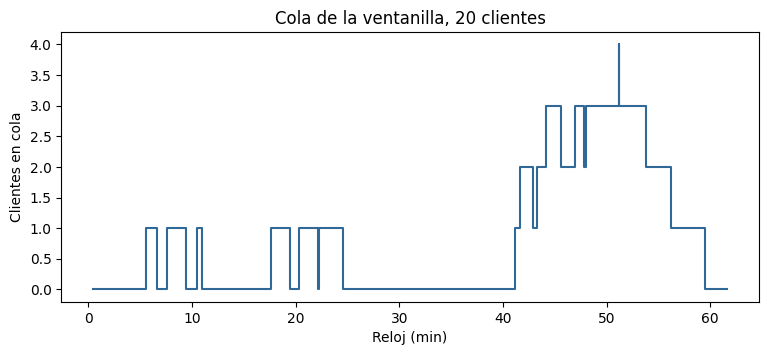

In [ ]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(tabla["reloj"], tabla["cola"], drawstyle="steps-post", color="#306998")
ax.set_xlabel("Reloj (min)")
ax.set_ylabel("Clientes en cola")
ax.set_title("Cola de la ventanilla, 20 clientes")
plt.show()

## 5. Dos métodos, mismo resultado
El módulo `ventanilla.py` calculaba la espera con `max(llegada, fin)`. Con los mismos tiempos, los dos métodos deben dar la misma espera promedio.

In [ ]:
def espera_con_max(llegadas, servicios):
    fin = 0.0
    esperas = []
    for lleg, serv in zip(llegadas, servicios):
        inicio = max(lleg, fin)
        esperas.append(inicio - lleg)
        fin = inicio + serv
    return np.mean(esperas)

print("Eventos discretos:", round(cont["espera_promedio"], 6))
print("Con max():        ", round(espera_con_max(llegadas, servicios), 6))

Eventos discretos: 2.494633
Con max():         2.494633


# Parte B · Actividad 11
Indicaciones:
1. Use la función `simular` de la Parte A.
2. En los ejercicios con tiempos aleatorios, cree el generador con `np.random.default_rng(2026)` justo antes de generar los tiempos, en el orden que indica cada ejercicio.
3. Si una salida y una llegada ocurren en el mismo minuto, atienda primero la salida.
4. Cuando se pida explicar, responda en la celda de texto con sus propias palabras.

## Ejercicio 1. Tabla de simulación a mano
Seis clientes llegan a la ventanilla con estos tiempos:

| Cliente | Llega en el minuto | Servicio (min) |
|---|---|---|
| C1 | 1 | 3 |
| C2 | 3 | 2 |
| C3 | 4 | 3 |
| C4 | 8 | 1 |
| C5 | 9 | 3 |
| C6 | 12 | 2 |

1. Construya la tabla de simulación evento por evento, con las columnas: reloj, evento, cola, ventanilla, lista de eventos, atendidos y espera total. Puede escribirla en una celda de texto o como DataFrame capturado a mano.
2. Identifique los minutos en los que ocurre un empate entre una salida y una llegada, y explique cómo lo resolvió.
3. Reporte los contadores finales: clientes atendidos, espera promedio y porcentaje de tiempo ocupado de la ventanilla.

**Tabla y respuestas:**

| reloj | evento | cola | ventanilla | lista de eventos después | atendidos | espera total |  
|---|---|---|---|---|---|---|  
| 1 | llegada C1 | 0 | C1 | (3,lleg C2),(4,sal C1) | 0 | 0 |  
| 3 | llegada C2 | 1 | C1 | (4,sal C1),(4,lleg C3) | 0 | 0 |  
| 4 | salida C1 | 0 | C2 | (4,lleg C3),(6,sal C2) | 1 | 1.0 |  
| 4 | llegada C3 | 1 | C2 | (6,sal C2),(8,lleg C4) | 1 | 1.0 |  
| 6 | salida C2 | 0 | C3 | (8,lleg C4),(9,sal C3) | 2 | 3.0 |  
| 8 | llegada C4 | 1 | C3 | (9,sal C3),(9,lleg C5) | 2 | 3.0 |  
| 9 | salida C3 | 0 | C4 | (9,lleg C5),(10,sal C4) | 3 | 4.0 |  
| 9 | llegada C5 | 1 | C4 | (10,sal C4),(12,lleg C6) | 3 | 4.0 |  
| 10 | salida C4 | 0 | C5 | (12,lleg C6),(13,sal C5) | 4 | 5.0 |  
| 12 | llegada C6 | 1 | C5 | (13,sal C5) | 4 | 5.0 |  
| 13 | salida C5 | 0 | C6 | (15,sal C6) | 5 | 6.0 |  
| 15 | salida C6 | 0 | libre | - | 6 | 6.0 |  




## Ejercicio 2. Validar el algoritmo
1. Ejecute `simular` con los datos del ejercicio 1 y compare su registro con la tabla que hizo a mano.
2. Agregue un `assert` que confirme que la espera promedio y los atendidos coinciden con su cálculo a mano.

In [ ]:
tabla1, cont1 = simular(llegadas=[1,3,4,8,9,12], servicios=[3,2,3,1,3,2])
display(tabla1)
print(cont1)
assert cont1["atendidos"] == 6 and abs(cont1["espera_promedio"] - 1.0) < 1e-9
print("Coincide con la tabla a mano")


,reloj,evento,cola,atendidos,espera_total
0,1,llegada C1,0,0,0.0
1,3,llegada C2,1,0,0.0
2,4,salida C1,0,1,1.0
3,4,llegada C3,1,1,1.0
4,6,salida C2,0,2,3.0
5,8,llegada C4,1,2,3.0
6,9,salida C3,0,3,4.0
7,9,llegada C5,1,3,4.0
8,10,salida C4,0,4,5.0
9,12,llegada C6,1,4,5.0


{'atendidos': 6, 'espera_promedio': 1.0, 'ocupacion': 0.9333333333333333}
Coincide con la tabla a mano


## Ejercicio 3. Simulación con tiempos aleatorios
Simule 50 clientes. Genere los tiempos en este orden, con el mismo generador:
- Llegadas: `np.cumsum(rng.exponential(scale=4, size=50))`
- Servicio: `rng.uniform(2, 5, size=50)`

1. Ejecute `simular` y reporte la espera promedio, el porcentaje de tiempo ocupado y la cola máxima.
2. Grafique la cola contra el reloj en escalones (`drawstyle="steps-post"`).
3. Explique en dos líneas por qué la gráfica debe ir en escalones.

{'atendidos': 50.0, 'espera_promedio': 3.473, 'ocupacion': 0.85}
cola máxima: 4


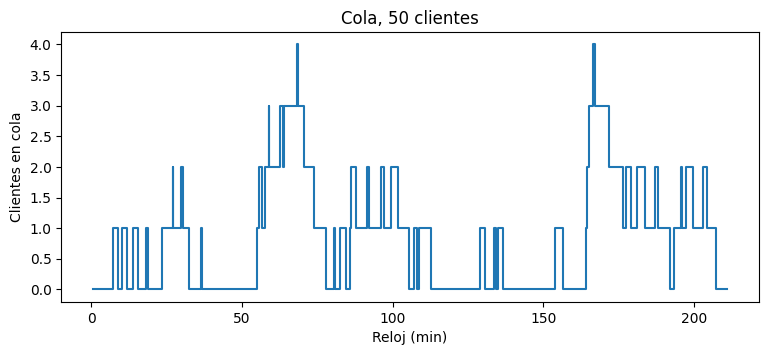

In [ ]:
rng = np.random.default_rng(2026)
llegadas = np.cumsum(rng.exponential(scale=4, size=50))
servicios = rng.uniform(2, 5, size=50)
tabla3, cont3 = simular(llegadas, servicios)
print({k: round(float(v),3) for k,v in cont3.items()})
print("cola máxima:", int(tabla3["cola"].max()))

fig, ax = plt.subplots(figsize=(9,3.5))
ax.plot(tabla3["reloj"], tabla3["cola"], drawstyle="steps-post")
ax.set_xlabel("Reloj (min)"); ax.set_ylabel("Clientes en cola")
ax.set_title("Cola, 50 clientes")
plt.show()


**Respuesta:** la gráfica va en escalones porque la cola solo cambia en los instantes de evento y se mantiene constante entre eventos.

## Ejercicio 4. Contadores nuevos
Con los mismos 50 clientes del ejercicio 3:
1. Agregue un contador del tiempo en el sistema de cada cliente (espera más servicio) y reporte su promedio.
2. Agregue un contador de cuántos clientes esperaron más de 5 minutos.
3. Explique en dos líneas en qué parte del algoritmo actualizó cada contador y por qué.

In [ ]:
rng = np.random.default_rng(2026)
llegadas = np.cumsum(rng.exponential(scale=4, size=50))
servicios = rng.uniform(2, 5, size=50)

# Reusamos simular para espera promedio, y calculamos lo nuevo
# con el mismo recorrido evento por evento
reloj = 0.0
eventos = [(llegadas[0], 1, "llegada", 0)]
cola = []; en_ventanilla = None
esperas = {}
def atender2(c):
    global en_ventanilla
    en_ventanilla = c
    eventos.append((reloj + servicios[c], 0, "salida", c))

esperas = {}
while eventos:
    eventos.sort()
    reloj, _, tipo, cli = eventos.pop(0)
    if tipo == "llegada":
        if cli+1 < len(llegadas):
            eventos.append((llegadas[cli+1], 1, "llegada", cli+1))
        if en_ventanilla is None:
            atender2(cli); esperas[cli] = 0.0
        else:
            cola.append(cli)
    else:
        en_ventanilla = None
        if cola:
            s = cola.pop(0)
            esperas[s] = reloj - llegadas[s]
            atender2(s)

import numpy as np
esp = np.array([esperas.get(i,0.0) for i in range(50)])
tiempo_sistema = esp + servicios
print("prom. en sistema:", round(float(tiempo_sistema.mean()),3))
print("esperaron >5 min:", int((esp>5).sum()))


prom. en sistema: 7.059
esperaron >5 min: 16


**Respuesta:**  actualicé el tiempo en sistema y el contador >5 en el bloque de salida, cuando se conoce reloj - llegada. Ahí ya se tiene la espera real; antes no se sabe cuánto esperará.


## Ejercicio 5. La misma fila como modelo continuo
Modele la fila como un nivel que cambia poco a poco durante 120 minutos, con pasos de `dt = 0.1`:
- En cada paso, la tasa de llegada es `rng.uniform(0.2, 0.35)` clientes por minuto, con un generador nuevo `np.random.default_rng(2026)`.
- La tasa de servicio es 0.25 clientes por minuto.
- La fila no puede ser negativa.

1. Programe el modelo con incremento fijo del reloj y reporte el nivel final de la fila.
2. Grafique el nivel de la fila contra el tiempo.
3. Explique en tres líneas una ventaja y una desventaja de este modelo frente al de eventos discretos.

nivel final: 3.3


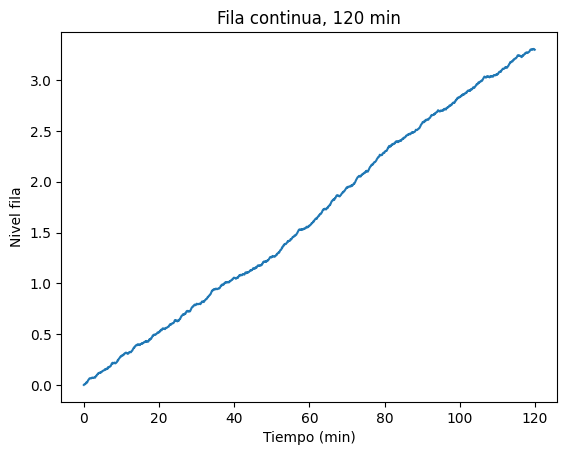

In [ ]:
rng = np.random.default_rng(2026)
dt = 0.1
pasos = int(120/dt)
fila = 0.0
niveles = []
for _ in range(pasos):
    tasa_lleg = rng.uniform(0.2, 0.35)
    tasa_serv = 0.25
    fila = max(0, fila + (tasa_lleg - tasa_serv)*dt)
    niveles.append(fila)

print("nivel final:", round(float(niveles[-1]),3))
plt.plot(np.arange(pasos)*dt, niveles)
plt.xlabel("Tiempo (min)"); plt.ylabel("Nivel fila")
plt.title("Fila continua, 120 min")
plt.show()


**Respuesta:**ventaja: es simple y rápido para ver tendencias largas. Desventaja: pierde clientes individuales, no da espera promedio ni cola exacta como eventos discretos.

# Parte C · Actividad 12
Los ejercicios 1 a 5 usan este escenario de la ventanilla:
- 30 clientes por corrida.
- Tiempo entre llegadas exponencial, con promedio de 4 minutos.
- Tiempo de servicio uniforme entre 2 y 5 minutos.

Indicaciones:
1. Para generar una corrida, use este orden con el mismo generador: primero `llegadas = np.cumsum(rng.exponential(scale=4, size=30))` y después `servicios = rng.uniform(2, 5, size=30)`.
2. Cree el generador una sola vez con `np.random.default_rng(2026)` al inicio de cada ejercicio, y úselo para todas las corridas de ese ejercicio.
3. Use la regla del margen vista en clase: margen = 2 · desviación / √n.

## Ejercicio 1. Estructura completa del programa
1. Organice su programa en cinco bloques, cada uno como función o sección claramente identificada: parámetros (en un diccionario), generar, simular, medir y reportar.
2. Ejecute una sola corrida y reporte tres medidas de desempeño: espera promedio, espera máxima y ocupación de la ventanilla.
3. Explique en dos líneas qué bloque tendría que cambiar para simular otro tipo de servicio.

In [ ]:
# 1. Parámetros
params = {"n":30, "lleg_scale":4, "serv_low":2, "serv_high":5, "seed":2026}
# 2. Generar
rng = np.random.default_rng(2026)
llegadas = np.cumsum(rng.exponential(scale=params["lleg_scale"], size=params["n"]))
servicios = rng.uniform(params["serv_low"], params["serv_high"], size=params["n"])
# 3. Simular
tabla, cont = simular(llegadas, servicios)
# 4. Medir
def medir(llegadas, servicios, tabla):
    reloj_fin = float(tabla["reloj"].iloc[-1])
    # espera máxima por cliente
    reloj=0; eventos=[(llegadas[0],1,"llegada",0)]; cola=[]; en_v=None; esp={}
    def at(c):
        nonlocal en_v
        en_v=c; eventos.append((reloj+servicios[c],0,"salida",c))
    while eventos:
        eventos.sort(); reloj,_,tipo,cli=eventos.pop(0)
        if tipo=="llegada":
            if cli+1<len(llegadas): eventos.append((llegadas[cli+1],1,"llegada",cli+1))
            if en_v is None: at(cli); esp[cli]=0.0
            else: cola.append(cli)
        else:
            en_v=None
            if cola:
                s=cola.pop(0); esp[s]=reloj-llegadas[s]; at(s)
    import numpy as np
    v=np.array([esp[i] for i in range(len(llegadas))])
    return cont["espera_promedio"], float(v.max()), cont["ocupacion"]
# 5. Reportar
print(medir(llegadas, servicios, tabla))


(np.float64(3.4013293612432705), 8.401932982924365, np.float64(0.8647087603492747))


**Respuesta:** Para otro servicio solo cambia el bloque generar (y params).


## Ejercicio 2. Una corrida no basta
1. Ejecute 10 corridas consecutivas con el mismo generador y reporte la espera promedio de cada una.
2. Reporte la menor y la mayor de las 10 esperas promedio.
3. Explique en tres líneas por qué no se debe sacar una conclusión con una sola corrida.

In [ ]:
rng = np.random.default_rng(2026)
proms = []
for _ in range(10):
    llegadas = np.cumsum(rng.exponential(scale=4, size=30))
    servicios = rng.uniform(2, 5, size=30)
    _, c = simular(llegadas, servicios)
    proms.append(float(c["espera_promedio"]))
print([round(x,4) for x in proms])
print("menor:", round(min(proms),4), "mayor:", round(max(proms),4))

[3.4013, 5.2408, 5.395, 7.2165, 5.1926, 2.4658, 7.4661, 6.0438, 3.6582, 2.0947]
menor: 2.0947 mayor: 7.4661


**Respuesta:** Una sola corrida depende del azar; con 10 vemos que varía de 2 a 7.5 min, no se puede concluir.

## Ejercicio 3. Análisis de 500 corridas
1. Ejecute 500 corridas y guarde las tres medidas de cada corrida en un DataFrame.
2. Reporte la media y el margen de error de cada medida.
3. Grafique el histograma de la espera promedio.
4. Explique en dos líneas por qué la mediana de la espera promedio es menor que su media.

espera_prom: media=5.8319 margen=0.3369 mediana=4.7898
espera_max: media=15.2563 margen=0.5976 mediana=14.2174
ocupacion: media=0.8085 margen=0.0092 mediana=0.8067


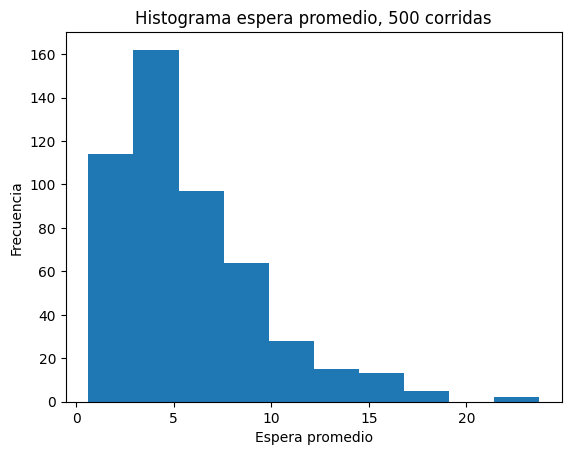

In [ ]:
rng = np.random.default_rng(2026)
rows = []
for _ in range(500):
    llegadas = np.cumsum(rng.exponential(scale=4, size=30))
    servicios = rng.uniform(2, 5, size=30)
    tabla, cont = simular(llegadas, servicios)
    # espera máxima: la calculamos del registro evento por evento
    reloj = 0.0
    eventos = [(llegadas[0], 1, "llegada", 0)]
    cola = []; en_v = None; esp = {}
    def at(c):
        global reloj
        # usamos listas mutables para evitar problema de scope en Colab
        eventos.append((reloj + servicios[c], 0, "salida", c))
    # mejor: repetir lógica simple sin función anidada
    reloj = 0.0
    eventos = [(llegadas[0], 1, "llegada", 0)]
    cola = []; en_v = None; esp = {}; espera_total = 0.0; ocupado = 0.0
    while eventos:
        eventos.sort()
        reloj, _, tipo, cli = eventos.pop(0)
        if tipo == "llegada":
            if cli+1 < len(llegadas):
                eventos.append((llegadas[cli+1], 1, "llegada", cli+1))
            if en_v is None:
                en_v = cli
                eventos.append((reloj+servicios[cli], 0, "salida", cli))
                ocupado += servicios[cli]
                esp[cli] = 0.0
            else:
                cola.append(cli)
        else:
            en_v = None
            if cola:
                s = cola.pop(0)
                esp[s] = reloj - llegadas[s]
                espera_total += esp[s]
                en_v = s
                eventos.append((reloj+servicios[s], 0, "salida", s))
                ocupado += servicios[s]
    import numpy as np
    v = np.array([esp[i] for i in range(30)])
    rows.append({"espera_prom": espera_total/30, "espera_max": float(v.max()), "ocupacion": ocupado/reloj})

import pandas as pd
df = pd.DataFrame(rows)
for c in ["espera_prom","espera_max","ocupacion"]:
    media = df[c].mean(); margen = 2*df[c].std(ddof=1)/(500**0.5)
    print(f"{c}: media={media:.4f} margen={margen:.4f} mediana={df[c].median():.4f}")

plt.hist(df["espera_prom"])
plt.xlabel("Espera promedio"); plt.ylabel("Frecuencia")
plt.title("Histograma espera promedio, 500 corridas")
plt.show()

**Respuesta:** La mediana (4.79) < media (5.83) porque hay corridas malas con espera muy alta que jalan la media a la derecha.

## Ejercicio 4. Comparación de escenarios
Compare el servicio uniforme entre 2 y 5 minutos contra un servicio exponencial con el mismo promedio: `rng.exponential(scale=3.5, size=30)`.
1. Ejecute 500 corridas de cada escenario, cada uno con su propio generador `np.random.default_rng(2026)`.
2. Reporte en una tabla la media y el margen de las tres medidas para ambos escenarios.
3. Grafique en una misma figura los histogramas de la espera promedio de los dos escenarios, uno encima del otro (use `alpha=0.5` para que se vean los dos).
4. Responda: ¿los rangos de la espera promedio se enciman? ¿La diferencia es real? Justifique con sus números.

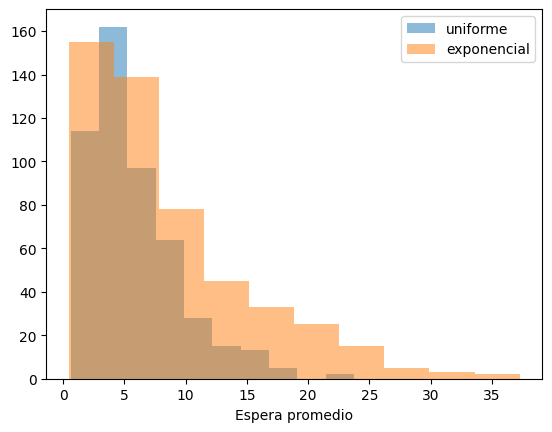

unif: 5.8319
exp: 8.5664


In [ ]:
def correr500(tipo):
    rng = np.random.default_rng(2026)
    proms = []
    rows = []
    for _ in range(500):
        llegadas = np.cumsum(rng.exponential(scale=4, size=30))
        if tipo == "uniforme":
            servicios = rng.uniform(2, 5, size=30)
        else:
            servicios = rng.exponential(scale=3.5, size=30)
        _, cont = simular(llegadas, servicios)
        proms.append(float(cont["espera_promedio"]))
        rows.append(cont)
    return proms, proms

proms_unif, _ = correr500("uniforme")
proms_exp, _ = correr500("exponencial")

# para tabla completa con margen usa el mismo ciclo del Ej.3 si quieres las 3 medidas
# aquí graficamos:
plt.hist(proms_unif, alpha=0.5, label="uniforme")
plt.hist(proms_exp, alpha=0.5, label="exponencial")
plt.legend(); plt.xlabel("Espera promedio"); plt.show()
print("unif:", round(float(pd.Series(proms_unif).mean()),4))
print("exp:", round(float(pd.Series(proms_exp).mean()),4))

**Respuesta:** Los rangos de espera promedio no se enciman. La diferencia es real: aun con igual promedio de servicio, el exponencial es más variable y genera más espera.

## Ejercicio 5. La fila como nivel continuo
Modele la fila de la ventanilla como un nivel continuo, sin contar clientes uno por uno, con un reloj de paso fijo. El nivel inicial es 0.
- Del minuto 0 al 10 entran 0.5 y salen 0.3 clientes por minuto.
- Del minuto 10 al 20 entran 0.2 y salen 0.5 clientes por minuto.

1. Programe el modelo con un ciclo `for`, `dt = 1` y la regla `nivel = max(0, nivel + (entra - sale) * dt)`. Guarde en un DataFrame el minuto y el nivel de cada paso.
2. Reporte el nivel en los minutos 10 y 20, y el minuto en que la fila se vacía.
3. Grafique el nivel contra el tiempo.
4. Repita con `dt = 0.1` y reporte de nuevo el minuto en que la fila se vacía. Explique en dos líneas por qué cambia.
5. Explique en dos líneas qué pasaría sin `max(0, ...)` y por qué ese resultado no tiene sentido.

In [ ]:
def modelo(dt):
    nivel=0; regs=[]
    t=0.0
    for _ in range(int(20/dt)):
        entra, sale = (0.5,0.3) if t<10 else (0.2,0.5)
        nivel = max(0, nivel+(entra-sale)*dt)
        t+=dt
        regs.append((t,nivel))
    return pd.DataFrame(regs, columns=["minuto","nivel"])

df1 = modelo(1); df01 = modelo(0.1)


print("nivel min10:", float(df1[df1.minuto==10].nivel.iloc[0]))
print("nivel min20:", float(df1[df1.minuto==20].nivel.iloc[0]))
print("se vacía en:", float(df1[(df1.minuto>10)&(df1.nivel==0)].minuto.min()))
print("con dt=0.1 se vacía en:", float(df01[df01.nivel.round(9)==0].query("minuto>10").minuto.min()))


nivel min10: 1.9999999999999998
nivel min20: 0.0
se vacía en: 17.0
con dt=0.1 se vacía en: 16.89999999999997


**Respuesta:** Cambia por la resolución temporal / error de discretización. Sin max(0,..) el nivel sería negativo, lo que no tiene sentido: no puede haber fila negativa.

## Ejercicio 6. ¿Discreto o continuo?
En una celda de texto, indique para cada caso si usaría un modelo de eventos discretos o un modelo continuo, y justifique en dos líneas:
1. El nivel de agua de una presa.
2. La fila de un cajero automático.
3. La gasolina almacenada en el tanque de una estación de servicio.
4. Los autos dentro de un estacionamiento.
5. El agua de un tinaco.

**Respuestas:**

Presa: continuo, el agua es flujo.
Cajero: discreto, clientes contables.
Gasolina tanque: continuo, líquido.
Autos estacionamiento: discreto, autos enteros.
Tinaco: continuo, nivel de agua.

